# 01 · Understand the portfolio and query its history

**Credit Risk Lab | IBM stages 1–5: business understanding → data understanding**

This notebook documents the data boundary before presenting SQL analysis. The question is whether six months of observed account behavior can rank existing credit-card accounts by recorded next-month default risk. It is not an application-approval model.

**Prerequisite:** install the project and run `python -m credit_risk.run --root .` from the repository root. This notebook reads the exact generated cohort and split manifest; it does not download another version or fit another model. Notebook outputs contain aggregate analysis rather than individual source-account records.

## 1. Reproduce the data boundary

The three partitions were fixed before model development. The complete cohort is used below only for structural integrity checks. Outcome-aware analysis uses training IDs. Validation and test outcomes do not enter this notebook's exploratory questions.

In [1]:
from pathlib import Path
import json
import sqlite3
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown, Image

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "pyproject.toml").exists() and (p / "src" / "credit_risk").exists()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook from inside the credit-risk-lab project.")
sys.path.insert(0, str(ROOT / "src"))
required = [ROOT / "data/processed/credit.csv", ROOT / "reports/split_manifest.csv"]
if not all(p.exists() for p in required):
    raise FileNotFoundError("Run `python -m credit_risk.run --root .` from the project root first.")
credit = pd.read_csv(required[0])
manifest = pd.read_csv(required[1])
assert credit["id"].is_unique and manifest["id"].is_unique
assert set(credit.id) == set(manifest.id)
assert set(manifest["split"]) == {"train", "validation", "test"}
train_ids = set(manifest.loc[manifest["split"].eq("train"), "id"])
train = credit.loc[credit.id.isin(train_ids)].copy()
sns.set_theme(style="whitegrid", palette=["#008b83", "#173c57", "#d58045", "#7869a7"])
plt.rcParams.update({"figure.figsize": (10, 4), "axes.spines.top": False,
                     "axes.spines.right": False, "figure.dpi": 110})
pd.options.display.float_format = "{:,.4f}".format
display(pd.DataFrame({"partition": manifest["split"].value_counts().index,
                      "accounts": manifest["split"].value_counts().values}))

,partition,accounts
0,train,18000
1,test,6000
2,validation,6000


## 2. Structural audit

An advertised complete dataset still needs independent checks. Identifier uniqueness, binary target encoding, numeric types, and declared columns are assertions; a failing assertion should stop the analysis rather than be hidden by a chart.

In [2]:
from credit_risk.features import STATUS, BILLS, PAYMENTS

expected_columns = {"id", "limit_bal", "sex", "education", "marriage", "age", "target",
                    *STATUS, *BILLS, *PAYMENTS}
assert set(credit.columns) == expected_columns
assert len(credit) == 30_000
assert set(credit["target"].unique()) == {0, 1}
assert not credit.isna().any().any()
assert credit.select_dtypes("number").shape[1] == len(expected_columns)

audit = pd.DataFrame({"dtype": credit.dtypes.astype(str),
                      "missing_cells": credit.isna().sum(),
                      "distinct_values": credit.nunique()})
display(audit)
display(pd.Series({"cohort_rows": len(credit), "columns": len(credit.columns),
                   "unique_ids": credit.id.nunique(),
                   "duplicate_predictor_profiles": int(credit.drop(columns=["id", "target"]).duplicated().sum())},
                  name="structural_audit").to_frame())

,dtype,missing_cells,distinct_values
id,int64,0,30000
limit_bal,int64,0,81
sex,int64,0,2
education,int64,0,7
marriage,int64,0,4
age,int64,0,56
pay_0,int64,0,11
pay_2,int64,0,11
pay_3,int64,0,11
pay_4,int64,0,11


,structural_audit
cohort_rows,30000
columns,25
unique_ids,30000
duplicate_predictor_profiles,56


**Interpretation:** duplicates of predictors are not necessarily duplicate customers. The unique source identifier and the field definitions need separate examination. Demographic categories are source-coded; completeness does not resolve ambiguous repayment codes.

## 3. Inspect the relational model

`customers` has one row per account, while `repayment_history` has six rows per account. Joining on the wrong key or counting history rows as customers would inflate the portfolio size. `split_manifest` permits explicit training-only queries.

In [3]:
database = ROOT / "data/processed/credit.sqlite"
if not database.exists():
    raise FileNotFoundError("The generated credit.sqlite database is required.")
with sqlite3.connect(database) as connection:
    tables = pd.read_sql_query("SELECT name FROM sqlite_master WHERE type='table' ORDER BY name", connection)
    display(tables)
    for table in ["customers", "repayment_history", "split_manifest"]:
        display(Markdown(f"**{table} schema**"))
        display(pd.read_sql_query(f"PRAGMA table_info({table})", connection)[["name", "type"]])
    integrity = pd.read_sql_query("""
        SELECT COUNT(*) AS history_rows,
               COUNT(DISTINCT customer_id) AS accounts,
               COUNT(DISTINCT month) AS months
        FROM repayment_history
    """, connection)
display(integrity)
assert int(integrity.loc[0, "history_rows"]) == 6 * len(credit)
assert int(integrity.loc[0, "accounts"]) == len(credit)

,name
0,customers
1,repayment_history
2,split_manifest


**customers schema**

,name,type
0,id,INTEGER
1,limit_bal,INTEGER
2,sex,INTEGER
3,education,INTEGER
4,marriage,INTEGER
5,age,INTEGER
6,target,INTEGER


**repayment_history schema**

,name,type
0,customer_id,INTEGER
1,repayment_status,INTEGER
2,bill_amount,INTEGER
3,payment_amount,INTEGER
4,month,TEXT


**split_manifest schema**

,name,type
0,id,INTEGER
1,split,TEXT


,history_rows,accounts,months
0,180000,30000,6


## 4. Answer five business questions in SQL

The saved queries demonstrate aggregation, `CASE` expressions, joins, and subqueries. The normalized history table makes six-month relationships explicit. Every outcome-aware query joins the training split.

1. What is the training base rate and scale?
2. How do observed outcomes vary by credit-limit band?
3. What repayment patterns distinguish account groups?
4. How do bill and payment summaries differ across the six months?
5. Which documented segments have above-average observed default rates?

In [4]:
sql_results = {}
with sqlite3.connect(database) as connection:
    for path in sorted((ROOT / "sql").glob("*.sql")):
        query = path.read_text(encoding="utf-8")
        result = pd.read_sql_query(query, connection)
        sql_results[path.stem] = result
        display(Markdown(f"### {path.stem.replace('_', ' ')}"))
        display(result)

### 01 portfolio overview

,customers,next_month_defaults,default_rate,average_credit_limit_ntd
0,18000,3982,0.2212,"167,730.6700"


### 02 limit bands

,limit_band,customers,defaults,default_rate
0,01_under_50k,2591,956,0.3690
1,02_50k_to_150k,6540,1639,0.2506
2,03_150k_to_300k,5839,977,0.1673
3,04_300k_plus,3030,410,0.1353


### 03 repayment patterns

,delayed_months,customers,default_rate,average_payment_ntd
0,0,11902,0.1144,"6,348.2600"
1,1,2657,0.2992,"3,836.7600"
2,2,1167,0.3993,"3,486.2500"
3,3,719,0.4979,"2,768.8900"
4,4,573,0.5742,"2,556.8900"
5,5,169,0.6213,"2,671.4700"
6,6,813,0.6986,"2,213.0000"


### 04 monthly behavior

,month,next_month_default,accounts,mean_bill_ntd,mean_payment_ntd,delayed_share
0,2005-04,0,14018,"39,203.1700","5,776.9900",0.0636
1,2005-04,1,3982,"38,467.2300","3,531.2100",0.2506
2,2005-05,0,14018,"40,794.4600","5,203.0800",0.0554
3,2005-05,1,3982,"39,745.6400","3,418.3900",0.2519
4,2005-06,0,14018,"44,049.3300","5,273.3700",0.0701
5,2005-06,1,3982,"42,122.6500","3,312.3000",0.2875
6,2005-07,0,14018,"47,937.1400","5,800.5600",0.0861
7,2005-07,1,3982,"45,140.0100","3,486.4800",0.3317
8,2005-08,0,14018,"50,189.5800","6,679.1400",0.0852
9,2005-08,1,3982,"47,244.8000","3,339.2900",0.3764


### 05 above average segments

,education,marriage,customers,default_rate
0,3,1,1710,0.2579
1,2,1,4114,0.2453
2,2,2,4225,0.2329
3,3,2,1123,0.2253


**Read these as associations.** A segment's higher observed rate is not evidence that changing a customer's limit or education would change their outcome. Compare sample sizes before emphasizing rate differences; small groups can have unstable averages.

## 5. A join-based consistency check

The next query returns the six historical months for training accounts. Its row-count check verifies join cardinality and guards against repeated customer matches.

,month,training_account_months,mean_payment_ntd,delayed_share
0,2005-04,18000,"5,280.1700",0.1049
1,2005-05,18000,"4,808.2700",0.0989
2,2005-06,18000,"4,839.5400",0.1182
3,2005-07,18000,"5,288.6400",0.1404
4,2005-08,18000,"5,940.2900",0.1496
5,2005-09,18000,"5,685.2000",0.2303


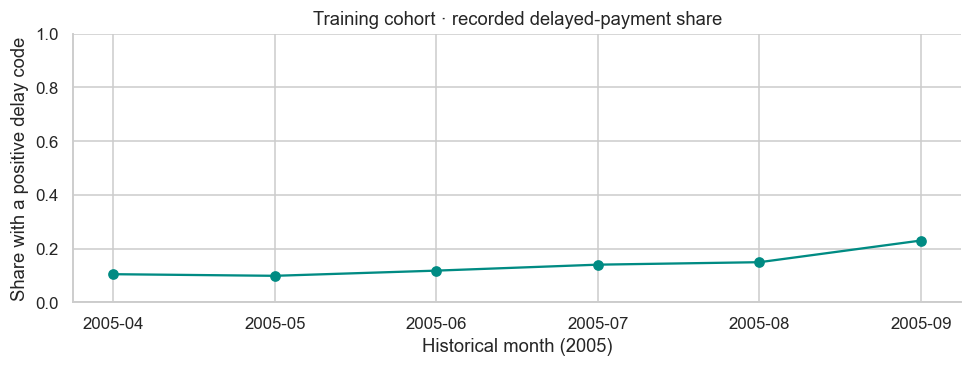

In [5]:
with sqlite3.connect(database) as connection:
    month_check = pd.read_sql_query("""
        SELECT h.month, COUNT(*) AS training_account_months,
               ROUND(AVG(h.payment_amount), 2) AS mean_payment_ntd,
               ROUND(AVG(CASE WHEN h.repayment_status > 0 THEN 1.0 ELSE 0.0 END), 4) AS delayed_share
        FROM repayment_history AS h
        JOIN customers AS c ON c.id = h.customer_id
        JOIN split_manifest AS s ON s.id = c.id
        WHERE s.split = 'train'
        GROUP BY h.month
        ORDER BY h.month
    """, connection)
display(month_check)
assert month_check.training_account_months.eq(len(train)).all()

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(month_check["month"], month_check["delayed_share"], marker="o", color="#008b83")
ax.set(title="Training cohort · recorded delayed-payment share", xlabel="Historical month (2005)",
       ylabel="Share with a positive delay code", ylim=(0, 1))
plt.tight_layout()
plt.show()

## 6. Provenance and conclusions

The provenance stored by the pipeline identifies the exact downloaded archive. The account cohort supplies a within-cohort evaluation, not an out-of-time backtest. The observed repayment months precede the outcome, but their presence does not create multiple independent calendar cohorts for temporal validation.

Proceed to notebook 02 for **training-only** statistical exploration. Field definitions and handling choices are in `docs/data_dictionary.md`; licensing and attribution are in `docs/references.md`.

In [6]:
provenance = json.loads((ROOT / "reports/provenance.json").read_text(encoding="utf-8"))
display(provenance)

{'source': 'https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients',
 'download_url': 'https://archive.ics.uci.edu/static/public/350/default+of+credit+card+clients.zip',
 'local_archive': 'data\\raw\\uci_credit_card.zip',
 'sha256': '56c885f84457f6680f8438f02bfcdac9579323d8a94465ee5f26e32baa727602',
 'bytes': 5539494,
 'audit_time_utc': '2026-11-06T13:25:02.430328+00:00',
 'license': 'CC BY 4.0 (source dataset); see DATA_LICENSE.md for attribution'}